# N-Grams

It's a probabilistic model that's trained on a corpus of text. Such a model is useful in many NLP applications including speech recognition, machine translation and predictive text input. An N-gram model is built by counting how often word sequences occur in corpus text and then estimating the probabilities.

## Types of N-Grams

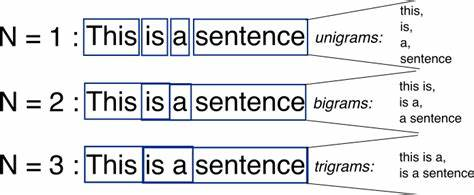

## Use-cases of N-Grams

- Auto completion of sentences
- Auto spell check
- Voice-based personal assistant bots

## Unigram

**Unigram** an n-gram consisting of a single item from a sequence.

- It is commonly used to calculate the probability of finding a word in an article.

$ count of (A) \div corpus length $

In [1]:
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

string = "moses supposes his toeses are roses but moses supposes erroneously"

unigrams = ngrams(word_tokenize(string), 1)

for item in unigrams:
    print(item)

('moses',)
('supposes',)
('his',)
('toeses',)
('are',)
('roses',)
('but',)
('moses',)
('supposes',)
('erroneously',)


### Calculating probabilities in unigram models

In [2]:
### Calculate counts of each word

unique_string = set(word_tokenize(string))

words_frq = []
for uniques in unique_string:
    frq = string.count(uniques)
    words_frq.append((uniques, frq))

words_frq

[('supposes', 2),
 ('but', 1),
 ('moses', 2),
 ('his', 1),
 ('erroneously', 1),
 ('toeses', 1),
 ('are', 1),
 ('roses', 1)]

In [3]:
### Calculate probabilities:

probab = []

for count in range(len(words_frq)):
    pro = words_frq[count][1]/len(string)
    probab.append(pro)

print('the probabilities are: ',probab)

the probabilities are:  [0.030303030303030304, 0.015151515151515152, 0.030303030303030304, 0.015151515151515152, 0.015151515151515152, 0.015151515151515152, 0.015151515151515152, 0.015151515151515152]


In [4]:
probabilities = []
for i,j in zip(unique_string, probab):
    probabilities.append((i,j))
probabilities

[('supposes', 0.030303030303030304),
 ('but', 0.015151515151515152),
 ('moses', 0.030303030303030304),
 ('his', 0.015151515151515152),
 ('erroneously', 0.015151515151515152),
 ('toeses', 0.015151515151515152),
 ('are', 0.015151515151515152),
 ('roses', 0.015151515151515152)]

## Bigram

**Bigram** an n-gram consisting of two items from a sequence
- Two words that are used together to mean something specific

$ countof(A \ then \ B) \div countof(A) $

### Method 1

In [5]:
import nltk as nl
from nltk.tokenize import word_tokenize

string = "moses supposes his toeses are roses but moses supposes erroneously"

bigrams = nl.bigrams(word_tokenize(string))
for i in bigrams:
    print(i)


('moses', 'supposes')
('supposes', 'his')
('his', 'toeses')
('toeses', 'are')
('are', 'roses')
('roses', 'but')
('but', 'moses')
('moses', 'supposes')
('supposes', 'erroneously')


### Method 2

In [6]:
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

string = "moses supposes his toeses are roses but moses supposes erroneously"

bigrams = ngrams(word_tokenize(string),2)

for i in bigrams:
    print(i)

('moses', 'supposes')
('supposes', 'his')
('his', 'toeses')
('toeses', 'are')
('are', 'roses')
('roses', 'but')
('but', 'moses')
('moses', 'supposes')
('supposes', 'erroneously')


# Trigram

**Trigram** an n-gram consisting of three items of a sequence
- Three words that are used together to mean something specific

### Method 1

In [7]:
import nltk as nl
from nltk.tokenize import word_tokenize

string = "moses supposes his toeses are roses but moses supposes erroneously"

trigrams = nl.trigrams(word_tokenize(string))

for i in trigrams:
    print(i)


('moses', 'supposes', 'his')
('supposes', 'his', 'toeses')
('his', 'toeses', 'are')
('toeses', 'are', 'roses')
('are', 'roses', 'but')
('roses', 'but', 'moses')
('but', 'moses', 'supposes')
('moses', 'supposes', 'erroneously')


### Method 2

In [8]:
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

string = "moses supposes his toeses are roses but moses supposes erroneously"

trigrams = ngrams(word_tokenize(string),3)

for i in trigrams:
    print(i)


('moses', 'supposes', 'his')
('supposes', 'his', 'toeses')
('his', 'toeses', 'are')
('toeses', 'are', 'roses')
('are', 'roses', 'but')
('roses', 'but', 'moses')
('but', 'moses', 'supposes')
('moses', 'supposes', 'erroneously')


## What is padding in NLP?

padding is a technique used to ensure that all input sequences have the same length. This is necessary because neural networks require inputs that have the same shape and size. However, when we pre-process and use texts as inputs for our model, not all sentences have the same length. In other words, some sentences are longer or shorter than others. We need to have inputs with the same size, and this is where padding comes in 1.

Padding is a special form of masking where the masked steps are at the start or the end of a sequence. Padding comes from the need to encode sequence data into contiguous batches: in order to make all sequences in a batch fit a given standard length.
The padding is added before splitting the sentence.

n-1 padding is added.



In [9]:
from nltk.util import ngrams
from nltk.tokenize import word_tokenize


string = "moses supposes his toeses are roses but moses supposes erroneously"

list(ngrams(word_tokenize(string), pad_left=True, left_pad_symbol="<s>",
                                pad_right=True, right_pad_symbol="</s>", n=2))

[('<s>', 'moses'),
 ('moses', 'supposes'),
 ('supposes', 'his'),
 ('his', 'toeses'),
 ('toeses', 'are'),
 ('are', 'roses'),
 ('roses', 'but'),
 ('but', 'moses'),
 ('moses', 'supposes'),
 ('supposes', 'erroneously'),
 ('erroneously', '</s>')]

Alternatively, We can get rid of the parameters by using
> pad_both_ends method in NLTK

**Note the n argument, that tells the function we need padding for bigrams.**

In [10]:
from nltk.lm.preprocessing import pad_both_ends
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

string = "moses supposes his toeses are roses but moses supposes erroneously"

list(ngrams(pad_both_ends(word_tokenize(string), n=2), n=2))


[('<s>', 'moses'),
 ('moses', 'supposes'),
 ('supposes', 'his'),
 ('his', 'toeses'),
 ('toeses', 'are'),
 ('are', 'roses'),
 ('roses', 'but'),
 ('but', 'moses'),
 ('moses', 'supposes'),
 ('supposes', 'erroneously'),
 ('erroneously', '</s>')]

### Training the Maximum Likelihood Model

Maximum likelihood estimation estimates the model parameters such that the probability is maximized.

- Get the requisite n_grams frequency counts from a corpus.

- Normalize them to a 0-1 range.

- Build the vocabulary: to create this vocabulary we need to pad our sentences (just like for counting ngrams) and then combine the sentences into one flat stream of words.


To do the above steps, we need to create and Ngram and add the padding then flatten the list. All these steps are requested for pre-processing to train the MLE model. However, we can use padded_everygram_pipeline() in NLTK to do all the steps in one call.


**References:**

https://www.nltk.org/api/nltk.lm.html

https://www.kaggle.com/code/alvations/n-gram-language-model-with-nltk

In [11]:
from nltk.lm.preprocessing import padded_everygram_pipeline
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from nltk.lm import smoothing

string = "moses supposes his toeses are roses but moses supposes erroneously"

#Create Bigram Language Model
train, vocab = padded_everygram_pipeline(2, [word_tokenize(string)])

In [12]:
from nltk.lm import MLE
lm = MLE(2)
lm.fit(train, vocab) #Train the Maximum Likelihood Model
print(lm.vocab)
print(len(lm.vocab))

<Vocabulary with cutoff=1 unk_label='<UNK>' and 11 items>
11


In [13]:
lm.vocab.lookup(['moses','supposes'])

('moses', 'supposes')

In [14]:
lm.vocab.lookup(['moses'])

('moses',)

### counts for unigrams and bigrams

In [15]:
print(lm.counts['moses'])
# a then b
print(lm.counts[['moses']]['supposes'])

2
2


In [16]:
print(lm.score('moses')) #Calculate Bigram Probabilities

0.16666666666666666


Here’s how you get the score for a word given some preceding context. For example we want to know what is the chance that “b” is preceded by “a”.

In [17]:
# b then a
lm.score("supposes", ["moses"])

1.0

### Evaluating n_grams models using preplexity

**Preplexity** is the probability of the test set normalized by the number of words

In [18]:
test = [('moses', 'supposes'), ('toeses','are')]
print(lm.perplexity(test))

1.0


# LAB3 - Part 1

## Example: Trigram model of the Reuters corpus

In this lab, we will use the `nltk` library for building N-gram model.

In [19]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


We will build a basic N-gram model using **trigrams** of the Reuters corpus. Reuters corpus is a collection of 10,788 news documents totaling 1.3 million words.

To download the dataset: `nltk.download()` opens the NLTK Downloader window where you search for the Reuters corpus and download it. Here we download it directly by its name:

In [20]:
import nltk
nltk.download('reuters')

[nltk_data] Downloading package reuters to
[nltk_data]     C:\Users\kemo7\AppData\Roaming\nltk_data...
[nltk_data]   Package reuters is already up-to-date!


True

Import the important libraries:

In [21]:
from nltk.corpus import reuters
from nltk import trigrams
from collections import Counter, defaultdict

**Note:** `defaultdict` is the same as the normal dictionary except for the fact that `defaultdict` never raises a `KeyError`.

The `defaultdict` will be the N-gram model:

In [22]:
model = defaultdict(lambda: defaultdict(lambda: 0))

Now we need to count the frequency of co-occurrence and save it in the `defaultdict`:

In [23]:
for sentence in reuters.sents():
    for w1, w2, w3 in trigrams(sentence, pad_right=True, pad_left=True):
        model[(w1, w2)][w3] += 1

The final step is to transform the counts into probabilities:

In [24]:
for w1_w2 in model:
    total_count = float(sum(model[w1_w2].values()))
    for w3 in model[w1_w2]:
        model[w1_w2][w3] /= total_count

Let's try the N-gram model to predict the next word:

In [25]:
print(dict(model['price', 'is']))

{'pre': 0.023255813953488372, 'subject': 0.06976744186046512, 'quoted': 0.023255813953488372, 'weighted': 0.023255813953488372, 'payable': 0.023255813953488372, 'at': 0.046511627906976744, 'above': 0.023255813953488372, 'about': 0.06976744186046512, 'suject': 0.023255813953488372, 'approximately': 0.023255813953488372, 'similar': 0.023255813953488372, 'fair': 0.023255813953488372, '18': 0.023255813953488372, '19': 0.023255813953488372, 'reduced': 0.023255813953488372, 'usually': 0.023255813953488372, '50': 0.023255813953488372, 'too': 0.023255813953488372, 'very': 0.023255813953488372, 'to': 0.023255813953488372, 'now': 0.046511627906976744, 'calculated': 0.023255813953488372, 'relatively': 0.023255813953488372, 'in': 0.023255813953488372, 'likely': 0.023255813953488372, 'based': 0.046511627906976744, 'not': 0.023255813953488372, 'lower': 0.023255813953488372, 'around': 0.023255813953488372, 'revised': 0.046511627906976744, 'then': 0.023255813953488372, 'paid': 0.023255813953488372, '1

To generate a random piece of text using our N-gram model (**Note:** you may see different outputs when you run the code below):

In [26]:
import random

text = ["today", "the"]
sentence_finished = False

while not sentence_finished:
    r = random.random()
    accumulator = .0

    for word in model[tuple(text[-2:])].keys():
        accumulator += model[tuple(text[-2:])][word]
        if accumulator >= r:
            text.append(word)
            break

    if text[-2:] == [None, None]:
        sentence_finished = True

print(' '.join([t for t in text if t]))

today the European space industry .


_____________________________________________________________________________________________

## Task#1: Generating tweets using N_grams

In this task, we will build a **MLE model with Bigram** to generate tweets.

The steps are:
1. Load the data — [Anonymous - Random Tweets | Kaggle](https://www.kaggle.com/datasets/adizafar/large-random-tweets-from-pakistan)
2. Pre-processing the data, where data cleaning included:
    * Remove any mentions
    * Remove hashtags
    * Remove RT
    * Remove any website
    * Removing extra symbols
    * Removing extra spaces
3. Build an MLE model with Bigram
4. Evaluate the model

Before starting, you need to install a library to handle the emojis in tweets
> pip install emoji

After building the model, calculate the following:
* Count of unigram `'pakistan'`
* Count of bigram `'is/pakistan'`
* Count of trigram `'a/pakistan is'`
* The probability of `'pakistan'` given `<s>`
* The probability of `'is'` given `'pakistan'`
* The probability of `'a'` given `'pakistan is'`
* Perplexity of the model.

In [27]:
%pip install emoji

Note: you may need to restart the kernel to use updated packages.


### 1. Load the data

In [28]:
import re
import emoji
import pandas as pd

# The file contains a few broken UTF-8 bytes, so they are replaced instead of raising an error
tweets = pd.read_csv('Random Tweets from Pakistan- Cleaned- Anonymous.csv',
                     encoding='utf-8', encoding_errors='replace', low_memory=False)

print('Shape of the dataset:', tweets.shape)
tweets.head()

Shape of the dataset: (202202, 7)


,Unnamed: 0,created_at_tweet,full_text,retweet_count,favorite_count,reply_count,location
0,0,Wed Jul 03 07:20:15 +0000 2019,تیرا لیڈر میرا لیڈر نواز شریف نواز شریف❤️ کیا...,226,1097,127,"Punjab, Pakistan"
1,1,Fri Jul 02 02:50:53 +0000 2021,"Happy birthday to my brother n boss , May you ...",54,273,9,"Punjab, Pakistan"
2,2,Fri Jul 02 12:12:53 +0000 2021,❤️❤️,50,131,13,"Punjab, Pakistan"
3,3,Tue Oct 15 22:29:16 +0000 2019,`suspicious °jikook au jimin'in yaşadığı kasab...,522,2134,86,"İstanbul, Türkiye"
4,4,Wed May 13 04:34:31 +0000 2020,Speaking of @SpiderMan... 😂 https://t.co/uGJ...,74,535,11,Follow the ATP Tour ➡


In [29]:
tweets = tweets[['full_text']].dropna().reset_index(drop=True)
print('Number of tweets:', len(tweets))
tweets['full_text'].head(10).tolist()

Number of tweets: 202151


['تیرا لیڈر میرا لیڈر نواز شریف نواز شریف❤️  کیا آپکا بھی ھے؟؟؟ @MaryamNSharif @Tanverhussan @SenPervaiz https://t.co/mDyOGs3sXv',
 'Happy birthday to my brother n boss , May you have many many more🎂🎂🎂, you are Gem 💎 #HappyBirthdayAtifRauf',
 '❤️❤️',
 "`suspicious °jikook au jimin'in yaşadığı kasabada aniden başlayan cinayetler, onun kendisini sürekli takip eden yeni komşusu jungkook'tan şüphelenmesine neden olur https://t.co/QJA6XaDtVh",
 'Speaking of @SpiderMan... 😂   https://t.co/uGJFiREUl8',
 'Alexa, skip to 2021',
 'Jb tm moon lover ho gy to sooraj to tappy ga na 😒',
 'Alexa skip to 2022 now',
 'But this was one of my first shoots, about 6 years ago 😊 https://t.co/w9Aua3q5qb',
 'Trying phoneix in 140 ping 🔥 https://t.co/CpjY4hZEjl']

### 2. Pre-processing the data

In [30]:
def clean_tweet(text):
    text = str(text)
    text = re.sub(r'\bRT\b', ' ', text)                    # Remove RT
    text = re.sub(r'@\w+', ' ', text)                       # Remove any mentions
    text = re.sub(r'#\w+', ' ', text)                       # Remove hashtags
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)      # Remove any website
    text = emoji.replace_emoji(text, replace=' ')           # Remove emojis
    text = re.sub(r'[^\w\s]|_', ' ', text)                 # Removing extra symbols
    text = re.sub(r'\s+', ' ', text).strip()                # Removing extra spaces
    return text.lower()

tweets['clean_text'] = tweets['full_text'].apply(clean_tweet)

# drop the tweets that became empty after cleaning (e.g. tweets with only emojis / links)
tweets = tweets[tweets['clean_text'] != ''].reset_index(drop=True)
print('Number of tweets after cleaning:', len(tweets))
tweets.head(10)

Number of tweets after cleaning: 180900


,full_text,clean_text
0,تیرا لیڈر میرا لیڈر نواز شریف نواز شریف❤️ کیا...,تیرا لیڈر میرا لیڈر نواز شریف نواز شریف کیا آپ...
1,"Happy birthday to my brother n boss , May you ...",happy birthday to my brother n boss may you ha...
2,`suspicious °jikook au jimin'in yaşadığı kasab...,suspicious jikook au jimin in yaşadığı kasabad...
3,Speaking of @SpiderMan... 😂 https://t.co/uGJ...,speaking of
4,"Alexa, skip to 2021",alexa skip to 2021
5,Jb tm moon lover ho gy to sooraj to tappy ga na 😒,jb tm moon lover ho gy to sooraj to tappy ga na
6,Alexa skip to 2022 now,alexa skip to 2022 now
7,"But this was one of my first shoots, about 6 y...",but this was one of my first shoots about 6 ye...
8,Trying phoneix in 140 ping 🔥 https://t.co/CpjY...,trying phoneix in 140 ping
9,Cant sleep 🥵🥱 So why not . https://t.co/WjmRMB...,cant sleep so why not


In [31]:
from nltk.tokenize import word_tokenize

tokenized_tweets = [word_tokenize(tweet) for tweet in tweets['clean_text']]
print('Total number of tokens:', sum(len(t) for t in tokenized_tweets))
tokenized_tweets[:3]

Total number of tokens: 3118052


[['تیرا',
  'لیڈر',
  'میرا',
  'لیڈر',
  'نواز',
  'شریف',
  'نواز',
  'شریف',
  'کیا',
  'آپکا',
  'بھی',
  'ھے'],
 ['happy',
  'birthday',
  'to',
  'my',
  'brother',
  'n',
  'boss',
  'may',
  'you',
  'have',
  'many',
  'many',
  'more',
  'you',
  'are',
  'gem'],
 ['suspicious',
  'jikook',
  'au',
  'jimin',
  'in',
  'yaşadığı',
  'kasabada',
  'aniden',
  'başlayan',
  'cinayetler',
  'onun',
  'kendisini',
  'sürekli',
  'takip',
  'eden',
  'yeni',
  'komşusu',
  'jungkook',
  'tan',
  'şüphelenmesine',
  'neden',
  'olur']]

### 3. Build an MLE model with Bigram

`padded_everygram_pipeline()` pads every tweet with `<s>` and `</s>`, creates the unigrams and bigrams, and builds the vocabulary.

In [32]:
from nltk.lm import MLE
from nltk.lm.preprocessing import padded_everygram_pipeline

n = 2
train_data, padded_vocab = padded_everygram_pipeline(n, tokenized_tweets)

bigram_model = MLE(n)
bigram_model.fit(train_data, padded_vocab)   # Train the Maximum Likelihood Model

print(bigram_model.vocab)
print('Vocabulary size:', len(bigram_model.vocab))

<Vocabulary with cutoff=1 unk_label='<UNK>' and 132371 items>
Vocabulary size: 132371


A bigram model only stores counts of unigrams and bigrams. To answer the questions about the **trigram** `'a/pakistan is'` (count and probability), we also train an MLE model of order 3 on the same pre-processed tweets.

In [33]:
train_data_3, padded_vocab_3 = padded_everygram_pipeline(3, tokenized_tweets)

trigram_model = MLE(3)
trigram_model.fit(train_data_3, padded_vocab_3)

print(trigram_model.vocab)

<Vocabulary with cutoff=1 unk_label='<UNK>' and 132371 items>


### Counts

In [34]:
# Count of unigram 'pakistan'
unigram_count = bigram_model.counts['pakistan']

# Count of bigram 'is/pakistan'  ->  'pakistan' then 'is'
bigram_count = bigram_model.counts[['pakistan']]['is']

# Count of trigram 'a/pakistan is'  ->  'pakistan is' then 'a'
trigram_count = trigram_model.counts[['pakistan', 'is']]['a']

print("Count of unigram 'pakistan'      :", unigram_count)
print("Count of bigram 'is/pakistan'    :", bigram_count)
print("Count of trigram 'a/pakistan is' :", trigram_count)

Count of unigram 'pakistan'      : 14009
Count of bigram 'is/pakistan'    : 697
Count of trigram 'a/pakistan is' : 70


### Probabilities

In [35]:
# P(pakistan | <s>)
p_pakistan_given_s = bigram_model.score('pakistan', ['<s>'])

# P(is | pakistan)
p_is_given_pakistan = bigram_model.score('is', ['pakistan'])

# P(a | pakistan is)
p_a_given_pakistan_is = trigram_model.score('a', ['pakistan', 'is'])

print("The probability of 'pakistan' given <s>    :", p_pakistan_given_s)
print("The probability of 'is' given 'pakistan'   :", p_is_given_pakistan)
print("The probability of 'a' given 'pakistan is' :", p_a_given_pakistan_is)

The probability of 'pakistan' given <s>    : 0.0076285240464344945
The probability of 'is' given 'pakistan'   : 0.04975372974516382
The probability of 'a' given 'pakistan is' : 0.10043041606886657


We can check the MLE formulas manually:

$P(w_i \mid w_{i-1}) = \dfrac{count(w_{i-1}\ w_i)}{count(w_{i-1})}$ and $P(w_i \mid w_{i-2}\ w_{i-1}) = \dfrac{count(w_{i-2}\ w_{i-1}\ w_i)}{count(w_{i-2}\ w_{i-1})}$

In [36]:
print("P(is | pakistan)   =", bigram_count, "/", unigram_count, "=", bigram_count / unigram_count)
print("P(a | pakistan is) =", trigram_count, "/", bigram_count, "=", trigram_count / bigram_count)

P(is | pakistan)   = 697 / 14009 = 0.04975372974516382
P(a | pakistan is) = 70 / 697 = 0.10043041606886657


### 4. Evaluate the model — Perplexity

**Perplexity** is the probability of the test set normalized by the number of words (lower is better).

We evaluate the bigram model on the padded bigrams of a sample of 1,000 tweets. Note that an MLE model gives a probability of 0 to any bigram it has never seen, which makes the perplexity infinite, so the evaluation bigrams are taken from the tweets the model was trained on.

In [37]:
from nltk.lm.preprocessing import pad_both_ends
from nltk.util import bigrams

test_tweets = tweets.sample(1000, random_state=42).index
test = [bg for i in test_tweets for bg in bigrams(pad_both_ends(tokenized_tweets[i], n=2))]
perplexity = bigram_model.perplexity(test)

print('Number of test bigrams :', len(test))
print('Example test bigrams   :', test[:5])
print('Perplexity of the model:', perplexity)

Number of test bigrams : 18101
Example test bigrams   : [('<s>', 'adana'), ('adana', 'gaziantep'), ('gaziantep', 'kahramanmaraş'), ('kahramanmaraş', 'kayseri'), ('kayseri', 'i̇tü')]
Perplexity of the model: 61.50261120194224


In [38]:
# Perplexity of a single tweet
tweet = tokenized_tweets[test_tweets[0]]
print('Tweet     :', ' '.join(tweet))
print('Perplexity:', bigram_model.perplexity(list(bigrams(pad_both_ends(tweet, n=2)))))

Tweet     : adana gaziantep kahramanmaraş kayseri i̇tü eta vakfı doğa kolejleri yönetim kurulu başkanımız uzm dr sayın halil gürsoy adana tenis dağ ve su sporları kulübü başkanı sayın ali refah keskin ile birlikte seyhan belediye başkanımızı ziyaret ettiler
Perplexity: 4.610683504865025


### Generating tweets using the bigram model

In [39]:
def generate_tweet(model, num_words=20, random_seed=None):
    words = []
    for word in model.generate(num_words, text_seed=['<s>'], random_seed=random_seed):
        if word == '</s>':
            break
        if word != '<s>':
            words.append(word)
    return ' '.join(words)

for seed in range(5):
    print(f'Tweet {seed + 1}:', generate_tweet(bigram_model, random_seed=seed))

Tweet 1: تباہ کن اثرات سے شروع کر پھولوں کو سلنڈر شاپ کا سوچیں تو پھر قوم سے کچھ ہوگیا ہمارے کئی


Tweet 2: clear to set a major general qamar javed bajwa
Tweet 3: پی کو اخلاقیات اور پسماندہ طبقات کی جانب سے متعلق صورت حال میں دم مست پتہ ہے دیکھیں حامد میر


Tweet 4: happiest birthday enjoying responsibility of all


Tweet 5: han


In [40]:
print('========== Results ==========')
print("Count of unigram 'pakistan'                :", unigram_count)
print("Count of bigram 'is/pakistan'              :", bigram_count)
print("Count of trigram 'a/pakistan is'           :", trigram_count)
print("The probability of 'pakistan' given <s>    :", p_pakistan_given_s)
print("The probability of 'is' given 'pakistan'   :", p_is_given_pakistan)
print("The probability of 'a' given 'pakistan is' :", p_a_given_pakistan_is)
print("Perplexity of the model                    :", perplexity)

========== Results ==========
Count of unigram 'pakistan'                : 14009
Count of bigram 'is/pakistan'              : 697
Count of trigram 'a/pakistan is'           : 70
The probability of 'pakistan' given <s>    : 0.0076285240464344945
The probability of 'is' given 'pakistan'   : 0.04975372974516382
The probability of 'a' given 'pakistan is' : 0.10043041606886657
Perplexity of the model                    : 61.50261120194224


# What I Learned from Lab 3 - Part 1

In this part I learned how **N-gram language models** work and how to build, use and evaluate them with NLTK.

### N-grams
- An N-gram is a sequence of N words: **unigram** (1 word), **bigram** (2 words) and **trigram** (3 words). N-grams are used in auto-completion, spell checking and voice assistants.
- An N-gram model predicts the next word from the previous N-1 words, using counts from a corpus.
- How to generate N-grams with `nltk.util.ngrams`, `nltk.bigrams` and `nltk.trigrams`.
- **Padding** adds the start `<s>` and end `</s>` symbols (n-1 of each), so the model can learn which words usually start and end a sentence. I can do it with `pad_left`/`pad_right` or with `pad_both_ends`.

### Trigram Model of the Reuters Corpus
- I built a trigram model from scratch with a `defaultdict`. First I counted how often each word follows every pair of words, then I divided by the total count to turn the counts into probabilities.
- The model can predict the next word (e.g. the possible words after `"price is"`) and generate random text starting from `"today the"`.
- A `defaultdict` never raises a `KeyError`, which makes counting much easier.

### Maximum Likelihood Estimation (MLE)
- MLE estimates probabilities directly from counts:
  $P(w_i \mid w_{i-1}) = \dfrac{count(w_{i-1}\ w_i)}{count(w_{i-1})}$
- `padded_everygram_pipeline()` does the padding, creates the N-grams and builds the vocabulary in one call. Then `MLE(n).fit()` trains the model.
- `lm.counts` gives the N-gram counts and `lm.score()` gives the probability of a word given its context.

### Generating Tweets Task
- I cleaned **202,202 tweets** with regular expressions: removing mentions, hashtags, `RT`, websites, symbols and extra spaces. I used the `emoji` library to remove emojis.
- I trained a bigram MLE model on about **3.1 million tokens** and got these results:
  - Count of `pakistan` = **14,009**, count of `pakistan is` = **697**, count of `pakistan is a` = **70**
  - P(`pakistan` | `<s>`) = **0.0076**, P(`is` | `pakistan`) = **0.0498**, P(`a` | `pakistan is`) = **0.1004**
- I checked the probabilities by hand with the MLE formula (e.g. 697 / 14009 = 0.0498), so I understand where the numbers come from.
- A bigram model only stores unigram and bigram counts. To get trigram counts and probabilities I needed a model of order 3.
- The model can generate new tweets, but they are often not very meaningful, because a bigram model only looks at one previous word.

### Evaluation with Perplexity
- **Perplexity** measures how well the model predicts a text. It is the inverse probability of the test set normalized by the number of words, and **lower is better**. My model got a perplexity of **61.5**.
- MLE gives a probability of **0** to any N-gram it has never seen, so the perplexity on new text becomes **infinite**. That is why smoothing methods (like Laplace) are needed in real applications.

**Conclusion:** N-gram models are simple and easy to understand, and they can predict and generate text. But they only look at a short context and they struggle with unseen word combinations.

_____________________________________________________________________________________________

# LAB3 - Part 2

## Task#1: Text Analysis and NLP

The steps are:
1. Load the dataset from a CSV file — [IMDB Dataset of 50K Movie Reviews | Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)
2. Pre-process the text data:
    * Tokenize the reviews into words.
    * Remove punctuation, and convert words to lowercase.
    * Remove common English stop words.
3. Calculate the following statistics:
    * Total number of reviews.
    * Average word count per review.
    * Number of positive reviews (containing the word "good") and negative reviews (containing the word "bad").
4. Create a word frequency histogram of the most common words in the reviews.
5. Print the results of the analysis.

### 1. Load the dataset from a CSV file

In [41]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download('punkt_tab')
nltk.download('stopwords')

imdb = pd.read_csv('IMDB Dataset.csv')
print('Shape of the dataset:', imdb.shape)
imdb.head()

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\kemo7\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kemo7\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Shape of the dataset: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### 2. Pre-process the text data

The reviews contain HTML line breaks (`<br />`), so they are removed first; otherwise `br` would appear as one of the most common words.

In [42]:
stop_words = set(stopwords.words('english'))

def preprocess(review):
    review = re.sub(r'<.*?>', ' ', review)                        # remove HTML tags such as <br />
    tokens = word_tokenize(review)                                 # tokenize the review into words
    tokens = [w.lower() for w in tokens                            # convert words to lowercase
              if w not in string.punctuation and w.isalpha()]      # remove punctuation
    tokens = [w for w in tokens if w not in stop_words]            # remove common English stop words
    return tokens

imdb['tokens'] = imdb['review'].apply(preprocess)
imdb[['review', 'tokens']].head()

,review,tokens
0,One of the other reviewers has mentioned that ...,"[one, reviewers, mentioned, watching, oz, epis..."
1,A wonderful little production. <br /><br />The...,"[wonderful, little, production, filming, techn..."
2,I thought this was a wonderful way to spend ti...,"[thought, wonderful, way, spend, time, hot, su..."
3,Basically there's a family where a little boy ...,"[basically, family, little, boy, jake, thinks,..."
4,"Petter Mattei's ""Love in the Time of Money"" is...","[petter, mattei, love, time, money, visually, ..."


### 3. Calculate the statistics

In [43]:
# Total number of reviews
total_reviews = len(imdb)

# Average word count per review
imdb['word_count'] = imdb['tokens'].apply(len)
avg_word_count = imdb['word_count'].mean()
avg_word_count_raw = imdb['review'].apply(lambda r: len(r.split())).mean()

# Number of positive reviews (containing the word "good") and negative reviews (containing the word "bad")
positive_reviews = imdb['tokens'].apply(lambda tokens: 'good' in tokens).sum()
negative_reviews = imdb['tokens'].apply(lambda tokens: 'bad' in tokens).sum()

print('Total number of reviews      :', total_reviews)
print('Average word count per review:', round(avg_word_count, 2))
print('Positive reviews ("good")    :', positive_reviews)
print('Negative reviews ("bad")     :', negative_reviews)

Total number of reviews      : 50000
Average word count per review: 114.65
Positive reviews ("good")    : 18693
Negative reviews ("bad")     : 11632


### 4. Word frequency histogram of the most common words

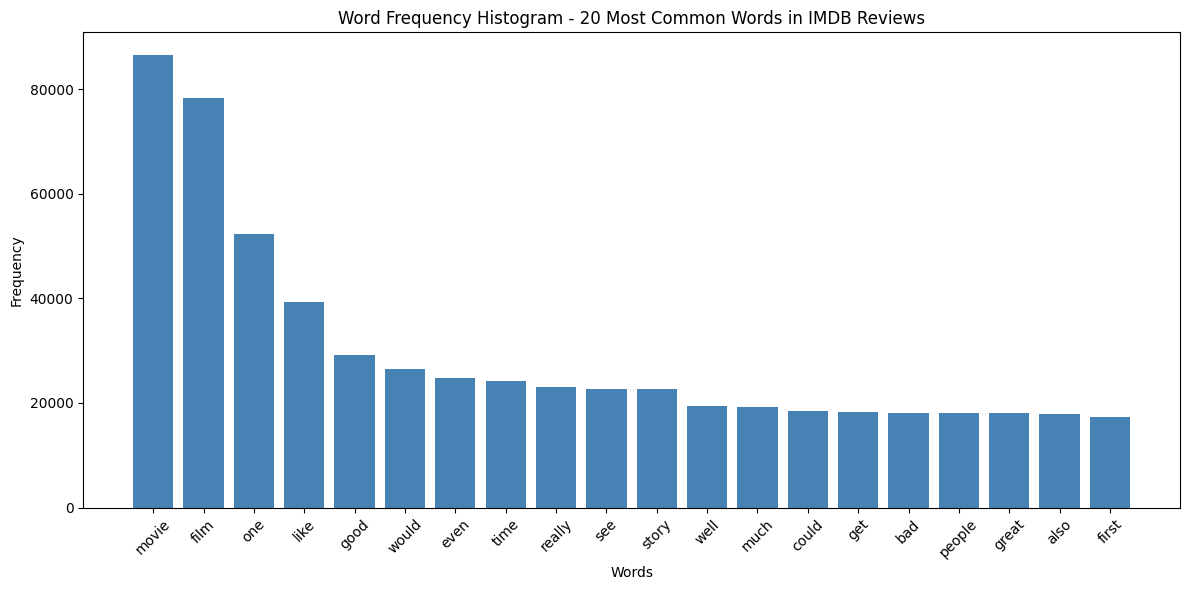

In [44]:
word_freq = Counter(word for tokens in imdb['tokens'] for word in tokens)
most_common_words = word_freq.most_common(20)

words, counts = zip(*most_common_words)

plt.figure(figsize=(12, 6))
plt.bar(words, counts, color='steelblue')
plt.title('Word Frequency Histogram - 20 Most Common Words in IMDB Reviews')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5. Print the results of the analysis

In [45]:
print('========== Results of the analysis ==========')
print('Total number of reviews                             :', total_reviews)
print('Average word count per review (after pre-processing):', round(avg_word_count, 2))
print('Average word count per review (original text)       :', round(avg_word_count_raw, 2))
print('Number of positive reviews (containing "good")      :', positive_reviews)
print('Number of negative reviews (containing "bad")       :', negative_reviews)
print()
print('20 most common words:')
for word, count in most_common_words:
    print(f'  {word:<10} {count}')

========== Results of the analysis ==========
Total number of reviews                             : 50000
Average word count per review (after pre-processing): 114.65
Average word count per review (original text)       : 231.16
Number of positive reviews (containing "good")      : 18693
Number of negative reviews (containing "bad")       : 11632

20 most common words:
  movie      86577
  film       78350
  one        52233
  like       39240
  good       29087
  would      26494
  even       24786
  time       24115
  really     23075
  see        22727
  story      22721
  well       19443
  much       19169
  could      18544
  get        18322
  bad        18135
  people     18120
  great      18025
  also       17910
  first      17250


_____________________________________________________________________________________________

## Task#2: N-gram Generation from Poem Data

The steps are:
1. Load the dataset from a CSV file — [Poem Classification (NLP) | Kaggle](https://www.kaggle.com/datasets/ramjasmaurya/poem-classification-nlp)
2. Pre-process the text data:
    * Tokenize the reviews into words.
    * Remove punctuation, and convert words to lowercase.
    * Remove common English stop words.
3. Generate bi-grams (2-grams) from the preprocessed text data.
4. Calculate the frequency of each unique bi-gram in the "bigrams" column.
5. Display the top 10 most common bi-grams.

### 1. Load the dataset from a CSV file

In [46]:
poems = pd.read_csv('Poem_classification - train_data.csv')
print('Shape of the dataset:', poems.shape)
print('Missing poems:', poems['Poem'].isna().sum())

poems = poems.dropna(subset=['Poem']).reset_index(drop=True)
print('Shape after removing missing poems:', poems.shape)
poems.head()

Shape of the dataset: (841, 2)
Missing poems: 4
Shape after removing missing poems: (837, 2)


,Genre,Poem
0,Music,In the thick brushthey spend the...
1,Music,Storms are generous. ...
2,Music,—After Ana Mendieta Did you carry around the ...
3,Music,for Aja Sherrard at 20The portent may itself ...
4,Music,"for Bob Marley, Bavaria, November 1980 Here i..."


### 2. Pre-process the text data

In [47]:
def preprocess_poem(poem):
    tokens = word_tokenize(poem)                                   # tokenize into words
    tokens = [w.lower() for w in tokens                            # convert words to lowercase
              if w not in string.punctuation and w.isalpha()]      # remove punctuation
    tokens = [w for w in tokens if w not in stop_words]            # remove common English stop words
    return tokens

poems['tokens'] = poems['Poem'].apply(preprocess_poem)
poems[['Poem', 'tokens']].head()

,Poem,tokens
0,In the thick brushthey spend the...,"[thick, brushthey, spend, hottest, part, day, ..."
1,Storms are generous. ...,"[storms, generous, something, easy, surrender,..."
2,—After Ana Mendieta Did you carry around the ...,"[ana, mendieta, carry, around, matin, star, ho..."
3,for Aja Sherrard at 20The portent may itself ...,"[aja, sherrard, portent, may, memory, wallace,..."
4,"for Bob Marley, Bavaria, November 1980 Here i...","[bob, marley, bavaria, november, brilliant, mo..."


### 3. Generate bi-grams (2-grams) from the preprocessed text data

In [48]:
from nltk.util import ngrams

poems['bigrams'] = poems['tokens'].apply(lambda tokens: list(ngrams(tokens, 2)))
poems[['tokens', 'bigrams']].head()

,tokens,bigrams
0,"[thick, brushthey, spend, hottest, part, day, ...","[(thick, brushthey), (brushthey, spend), (spen..."
1,"[storms, generous, something, easy, surrender,...","[(storms, generous), (generous, something), (s..."
2,"[ana, mendieta, carry, around, matin, star, ho...","[(ana, mendieta), (mendieta, carry), (carry, a..."
3,"[aja, sherrard, portent, may, memory, wallace,...","[(aja, sherrard), (sherrard, portent), (porten..."
4,"[bob, marley, bavaria, november, brilliant, mo...","[(bob, marley), (marley, bavaria), (bavaria, n..."


### 4. Calculate the frequency of each unique bi-gram in the "bigrams" column

In [49]:
bigram_freq = Counter(bigram for bigram_list in poems['bigrams'] for bigram in bigram_list)

print('Total number of bi-grams :', sum(bigram_freq.values()))
print('Number of unique bi-grams:', len(bigram_freq))

bigram_freq_df = (pd.DataFrame(bigram_freq.items(), columns=['bigram', 'frequency'])
                    .sort_values('frequency', ascending=False)
                    .reset_index(drop=True))
bigram_freq_df.head(20)

Total number of bi-grams : 19973
Number of unique bi-grams: 18308


,bigram,frequency
0,"(let, us)",10
1,"(ah, yes)",8
2,"(every, day)",7
3,"(first, time)",6
4,"(let, go)",6
5,"(come, back)",6
6,"(parking, lot)",6
7,"(give, us)",6
8,"(thou, art)",5
9,"(died, august)",5


### 5. Display the top 10 most common bi-grams

In [50]:
top_10_bigrams = bigram_freq.most_common(10)

print('Top 10 most common bi-grams:')
for rank, (bigram, count) in enumerate(top_10_bigrams, start=1):
    print(f'{rank:>2}. {" ".join(bigram):<20} {count}')

Top 10 most common bi-grams:
 1. let us               10
 2. ah yes               8
 3. every day            7
 4. let go               6
 5. first time           6
 6. come back            6
 7. parking lot          6
 8. give us              6
 9. died august          5
10. thou art             5


_____________________________________________________________________________________________

# What I Learned from Lab 3 - Part 2

In this part I used NLP techniques to analyze large text datasets and to find word patterns with bi-grams.

### Task 1: Text Analysis of IMDB Reviews
- I loaded a large dataset (**50,000 movie reviews**) with `pandas` and applied pre-processing to every review: tokenization, removing punctuation, lower casing and removing English stop words.
- I found that real data needs extra cleaning that is not always planned. For example, the reviews had HTML tags (`<br />`) that would have shown up as a common word if I had not removed them.
- Calculating statistics from text:
  - Total number of reviews: **50,000**
  - Average word count per review: **114.65** after pre-processing, compared to **231.16** in the original text. So pre-processing removed about half of the words, which are mostly stop words and punctuation.
  - Reviews containing "good": **18,693**, and reviews containing "bad": **11,632**
- Counting single words is a **very simple way to guess sentiment**. A review that contains "good" can still be negative (e.g. "not good").
- With `Counter` and a `matplotlib` histogram I saw that the most common words are `movie`, `film`, `one`, `like` and `good`. These words tell us the topic of the dataset but not much about each review.

### Task 2: Bi-grams from Poem Data
- I applied the same pre-processing steps to **837 poems** and generated bi-grams for each poem with `nltk.util.ngrams`, then saved them in a new `bigrams` column.
- I counted how often each unique bi-gram appears using `Counter`. There were **19,973 bi-grams**, and **18,308** of them were unique. This means most word pairs in poetry appear only once, because poems use very varied language.
- The top bi-grams were **"let us" (10)**, **"ah yes" (8)**, **"every day" (7)** and **"let go" (6)**. Bi-grams capture short phrases and expressions that single words cannot show.
- Some bi-grams such as `thick brushthey` came from words stuck together in the original data. The quality of the raw data directly affects the results.

**Conclusion:** Pre-processing turns raw text into clean tokens that can be counted and analyzed. Word frequencies and bi-grams are simple but useful tools for understanding what a large collection of text is about.